# 05 · E5: MNIST 1-Gizli-Katmanlı MLP (Konveks Olmayan)

**Amaç:** Reddi, Kale & Kumar (ICLR 2018) Bölüm 5.2 / Şekil 2'deki konveks olmayan MNIST MLP deneyini (`784 → 100 ReLU → 10`) ortak `PaperAdam` ve `PaperAMSGrad` implementasyonlarımızla yeniden üretmek.

**Adımlar (Proje Planı H2.2, H3.1):**
1. **Grid Search (`H2.2`):** `seed = 0` üzerinde `PaperAdam` vs `PaperAMSGrad`, sabit $\alpha \in \{10^{-4}, 3\cdot 10^{-4}, 10^{-3}, 3\cdot 10^{-3}, 10^{-2}\}$, $\beta_2 \in \{0.99, 0.999\}$, $\beta_1 = 0.9$, 5000 iterasyon, batch 128. Seçim kriteri: **son 500 iterasyonun ortalama train loss'u**.
2. **Final 5 Seed (`H3.1`):** Her iki optimizer için seçilen en iyi $(\alpha, \beta_2)$ ile `seed = 0, 1, 2, 3, 4` koşuları, Bölüm 2.2 formatında CSV kaydı (`results/e5_mnist_mlp/`) ve ortalama ± std figürü (`figures/e5.png` + `.pdf`).

**Kaggle ayarları:** Accelerator: **GPU T4**. MNIST Kaggle Dataset ekli ise internetsiz çalışır; yoksa `torchvision` fallback kullanılır.

## Makaleden sapmalar
- **Grid search $\alpha$ kümesi:** Makale grid search'te denenen sabit $\alpha$ değerlerini belirtmiyor. Her iki optimizer'a eşit bütçeyle $\alpha \in \{10^{-4}, 3\cdot 10^{-4}, 10^{-3}, 3\cdot 10^{-3}, 10^{-2}\}$ ve $\beta_2 \in \{0.99, 0.999\}$ tarandı; seçim kriteri önceden **son 500 iterasyonun ortalama minibatch train loss'u** olarak belirlendi.
- **$\varepsilon$ ve bias correction:** Makale gerçek veri deneylerinde $\varepsilon$ ve bias correction tercihlerini açıklamıyor. Bu deneyde `eps = 1e-8` ve `bias_correction = True` kullanıldı (her iki optimizer için aynı).
- **Veri ön işleme ve başlatma:** MNIST görüntüleri `[0, 1]`'e ölçeklenip standart normalize edildi (`mean = 0.1307`, `std = 0.3081`). Ağırlıklar PyTorch varsayılan Kaiming uniform ile başlatıldı.
- **Framework ve seed:** TensorFlow yerine PyTorch kullanıldı. Makalede tek eğri raporlanıyor; biz 5 seed (`0, 1, 2, 3, 4`) koşup ortalama ± std raporluyoruz. Aynı seed'de Adam ve AMSGrad aynı başlangıç ağırlıklarını ve aynı minibatch dizisini görür.
- **Değerlendirme metriği:** Her 50 iterasyonda tüm eğitim (60k) ve test (10k) kümeleri üzerinde Cross-Entropy loss ve test accuracy hesaplandı.

In [1]:
# --- Kurulum: repo ve cihaz ---
import os, sys, subprocess
REPO = "https://github.com/ybilgici/DeepLearning_Proje.git"
if os.path.exists("/kaggle"):
    ROOT = "/kaggle/working/DeepLearning_Proje"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", REPO, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
else:
    ROOT = os.path.abspath("..")
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from common.data import load_mnist
from common.mnist_exp import (
    build_mnist_mlp,
    plot_train_test_curves,
    run_final_seeds,
    run_grid_search,
    summarize_final_runs,
)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
RESULTS_DIR = os.path.join(ROOT, "results", "e5_mnist_mlp")
FIGURES_DIR = os.path.join(ROOT, "figures")
os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

print("Device:", DEVICE, "| torch:", torch.__version__)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Commit:", subprocess.run(["git", "-C", ROOT, "rev-parse", "--short", "HEAD"],
                                capture_output=True, text=True).stdout.strip())

Device: cuda | torch: 2.11.0+cu128
GPU: NVIDIA GeForce RTX 5070
Commit: d0b821c


In [2]:
# --- MNIST verisini GPU tensörleri olarak yükle (DataLoader yok) ---
X_train, y_train, X_test, y_test = load_mnist(device=DEVICE, flatten=True, normalize="standard")
print(f"X_train: {tuple(X_train.shape)} {X_train.dtype} on {X_train.device} | mean={X_train.mean():.3f}, std={X_train.std():.3f}")
print(f"X_test : {tuple(X_test.shape)} {X_test.dtype} on {X_test.device}")

X_train: (60000, 784) torch.float32 on cuda:0 | mean=-0.000, std=1.000
X_test : (10000, 784) torch.float32 on cuda:0


## 1. Grid Search (H2.2 — Seed 0)
Model: `784 → 100 ReLU → 10`. Sabit $\alpha \in \{10^{-4}, 3\cdot 10^{-4}, 10^{-3}, 3\cdot 10^{-3}, 10^{-2}\}$, $\beta_2 \in \{0.99, 0.999\}$, $\beta_1 = 0.9$, 5000 iterasyon, batch 128.
Seçim kriteri: **son 500 iterasyonun ortalama train loss'u**.

In [3]:
E5_LRS = [1e-4, 3e-4, 1e-3, 3e-3, 1e-2]
E5_BETA2S = [0.99, 0.999]
E5_STEPS = 5000
E5_BATCH = 128
E5_EPS = 1e-8
E5_BIAS_CORRECTION = True

grid_df, best_cfgs = run_grid_search(
    "e5",
    build_mnist_mlp,
    X_train, y_train, X_test, y_test,
    lrs=E5_LRS,
    beta2s=E5_BETA2S,
    beta1=0.9,
    eps=E5_EPS,
    bias_correction=E5_BIAS_CORRECTION,
    lr_schedule="const",
    steps=E5_STEPS,
    batch_size=E5_BATCH,
    seed=0,
    eval_every=250,
    selection_window=500,
)
grid_path = os.path.join(RESULTS_DIR, "grid_summary.csv")
grid_df.to_csv(grid_path, index=False)
print("\nGrid tablosu kaydedildi:", grid_path)
print("\nSeçilen en iyi konfigürasyonlar (son 500 iterasyon ortalama train loss'una göre):")
for opt_name, c in best_cfgs.items():
    print(f"  {opt_name:7s}: lr={c['lr']:g}, beta2={c['beta2']:g} -> last500={c['last500_train_loss']:.4f}, full_tr={c['final_train_loss']:.4f}, te_loss={c['final_test_loss']:.4f}, te_acc={c['final_test_acc']*100:.2f}%")

grid_df.sort_values(["optimizer", "last500_train_loss"]).reset_index(drop=True)

[adam   ] lr=0.0001  beta2=0.99  | last500_tr=0.1277 full_tr=0.1243 te_loss=0.1354 te_acc=95.94% (29.6s)


[adam   ] lr=0.0003  beta2=0.99  | last500_tr=0.0508 full_tr=0.0470 te_loss=0.0806 te_acc=97.62% (13.6s)


[adam   ] lr=0.001   beta2=0.99  | last500_tr=0.0221 full_tr=0.0205 te_loss=0.0894 te_acc=97.54% (12.4s)


[adam   ] lr=0.003   beta2=0.99  | last500_tr=0.0324 full_tr=0.0337 te_loss=0.1312 te_acc=97.23% (13.6s)


[adam   ] lr=0.01    beta2=0.99  | last500_tr=0.1043 full_tr=0.0953 te_loss=0.2121 te_acc=96.30% (13.9s)


[adam   ] lr=0.0001  beta2=0.999 | last500_tr=0.1354 full_tr=0.1319 te_loss=0.1424 te_acc=95.86% (12.9s)


... (11 outputs left out)

[amsgrad] lr=0.001   beta2=0.999 | last500_tr=0.0227 full_tr=0.0193 te_loss=0.0766 te_acc=97.62% (13.0s)


[amsgrad] lr=0.003   beta2=0.999 | last500_tr=0.0209 full_tr=0.0216 te_loss=0.1093 te_acc=97.46% (12.4s)


[amsgrad] lr=0.01    beta2=0.999 | last500_tr=0.0890 full_tr=0.1009 te_loss=0.2237 te_acc=96.03% (10.2s)

Grid tablosu kaydedildi: C:\Users\test\.gemini\antigravity\scratch\DeepLearning_Proje\results\e5_mnist_mlp\grid_summary.csv

Seçilen en iyi konfigürasyonlar (son 500 iterasyon ortalama train loss'una göre):
  adam   : lr=0.001, beta2=0.99 -> last500=0.0221, full_tr=0.0205, te_loss=0.0894, te_acc=97.54%
  amsgrad: lr=0.003, beta2=0.99 -> last500=0.0150, full_tr=0.0146, te_loss=0.0867, te_acc=97.57%


,exp,optimizer,seed,lr,beta1,beta2,last500_train_loss,final_train_loss,final_test_loss,final_test_acc,seconds
0,e5,adam,0,0.0010,0.9,0.990,0.022074,0.020532,0.089383,0.9754,12.40
1,e5,adam,0,0.0010,0.9,0.999,0.023896,0.022250,0.084285,0.9756,12.58
2,e5,adam,0,0.0030,0.9,0.990,0.032398,0.033717,0.131165,0.9723,13.56
3,e5,adam,0,0.0030,0.9,0.999,0.036328,0.045746,0.145886,0.9689,12.66
4,e5,adam,0,0.0003,0.9,0.990,0.050829,0.047036,0.080649,0.9762,13.57
5,e5,adam,0,0.0003,0.9,0.999,0.056234,0.052767,0.083711,0.9748,12.64
6,e5,adam,0,0.0100,0.9,0.990,0.104336,0.095345,0.212087,0.9630,13.88
7,e5,adam,0,0.0100,0.9,0.999,0.106171,0.109718,0.250607,0.9568,12.32
8,e5,adam,0,0.0001,0.9,0.990,0.127746,0.124336,0.135394,0.9594,29.56
9,e5,adam,0,0.0001,0.9,0.999,0.135448,0.131911,0.142425,0.9586,12.94


## 2. Final Koşuları (H3.1 — 5 Seed: `0, 1, 2, 3, 4`)
Her optimizer için grid search ile seçilen en iyi $(\alpha, \beta_2)$ çiftiyle 5 seed koşulur ve Bölüm 2.2 formatındaki CSV'ler `results/e5_mnist_mlp/` altına kaydedilir.

In [4]:
final_df = run_final_seeds(
    "e5",
    build_mnist_mlp,
    X_train, y_train, X_test, y_test,
    best_cfgs=best_cfgs,
    results_dir=RESULTS_DIR,
    seeds=(0, 1, 2, 3, 4),
    eps=E5_EPS,
    bias_correction=E5_BIAS_CORRECTION,
    lr_schedule="const",
    steps=E5_STEPS,
    batch_size=E5_BATCH,
    eval_every=50,
)

summary_df = summarize_final_runs(final_df)
for _, r in summary_df.iterrows():
    print(
        f"{r['optimizer']:7s} (lr={r['lr']:g}, b2={r['beta2']:g}, n={int(r['n_seeds'])}): "
        f"train_loss = {r['train_loss_mean']:.4f} ± {r['train_loss_std']:.4f} | "
        f"test_loss = {r['test_loss_mean']:.4f} ± {r['test_loss_std']:.4f} | "
        f"test_acc = {r['test_acc_mean']*100:.2f}% ± {r['test_acc_std']*100:.2f}%"
    )
summary_df

[FINAL adam   ] seed=0 lr=0.001   b2=0.99  | tr_loss=0.0205 te_loss=0.0894 te_acc=97.54% -> adam_seed0.csv


[FINAL adam   ] seed=1 lr=0.001   b2=0.99  | tr_loss=0.0238 te_loss=0.0847 te_acc=97.60% -> adam_seed1.csv


[FINAL adam   ] seed=2 lr=0.001   b2=0.99  | tr_loss=0.0163 te_loss=0.0783 te_acc=97.90% -> adam_seed2.csv


[FINAL adam   ] seed=3 lr=0.001   b2=0.99  | tr_loss=0.0169 te_loss=0.0812 te_acc=97.78% -> adam_seed3.csv


[FINAL adam   ] seed=4 lr=0.001   b2=0.99  | tr_loss=0.0224 te_loss=0.0870 te_acc=97.65% -> adam_seed4.csv


[FINAL amsgrad] seed=0 lr=0.003   b2=0.99  | tr_loss=0.0146 te_loss=0.0867 te_acc=97.57% -> amsgrad_seed0.csv


[FINAL amsgrad] seed=1 lr=0.003   b2=0.99  | tr_loss=0.0153 te_loss=0.0787 te_acc=97.73% -> amsgrad_seed1.csv


[FINAL amsgrad] seed=2 lr=0.003   b2=0.99  | tr_loss=0.0124 te_loss=0.0860 te_acc=97.87% -> amsgrad_seed2.csv


[FINAL amsgrad] seed=3 lr=0.003   b2=0.99  | tr_loss=0.0115 te_loss=0.0827 te_acc=97.79% -> amsgrad_seed3.csv


[FINAL amsgrad] seed=4 lr=0.003   b2=0.99  | tr_loss=0.0140 te_loss=0.0859 te_acc=97.71% -> amsgrad_seed4.csv
adam    (lr=0.001, b2=0.99, n=5): train_loss = 0.0200 ± 0.0033 | test_loss = 0.0841 ± 0.0044 | test_acc = 97.69% ± 0.15%
amsgrad (lr=0.003, b2=0.99, n=5): train_loss = 0.0135 ± 0.0016 | test_loss = 0.0840 ± 0.0033 | test_acc = 97.73% ± 0.11%


,optimizer,lr,beta1,beta2,n_seeds,train_loss_mean,train_loss_std,test_loss_mean,test_loss_std,test_acc_mean,test_acc_std
0,adam,0.001,0.9,0.99,5,0.019994,0.003290,0.084097,0.004446,0.97694,0.001452
1,amsgrad,0.003,0.9,0.99,5,0.013541,0.001564,0.083997,0.003335,0.97734,0.001108


## 3. Final Figürü (`figures/e5.png` ve `figures/e5.pdf`)
Adam kırmızı kesikli, AMSGrad mavi düz çizgi; 5 seed üzerinden ortalama ± std bandı.

Kaydedildi: C:\Users\test\.gemini\antigravity\scratch\DeepLearning_Proje\figures\e5.png / .pdf


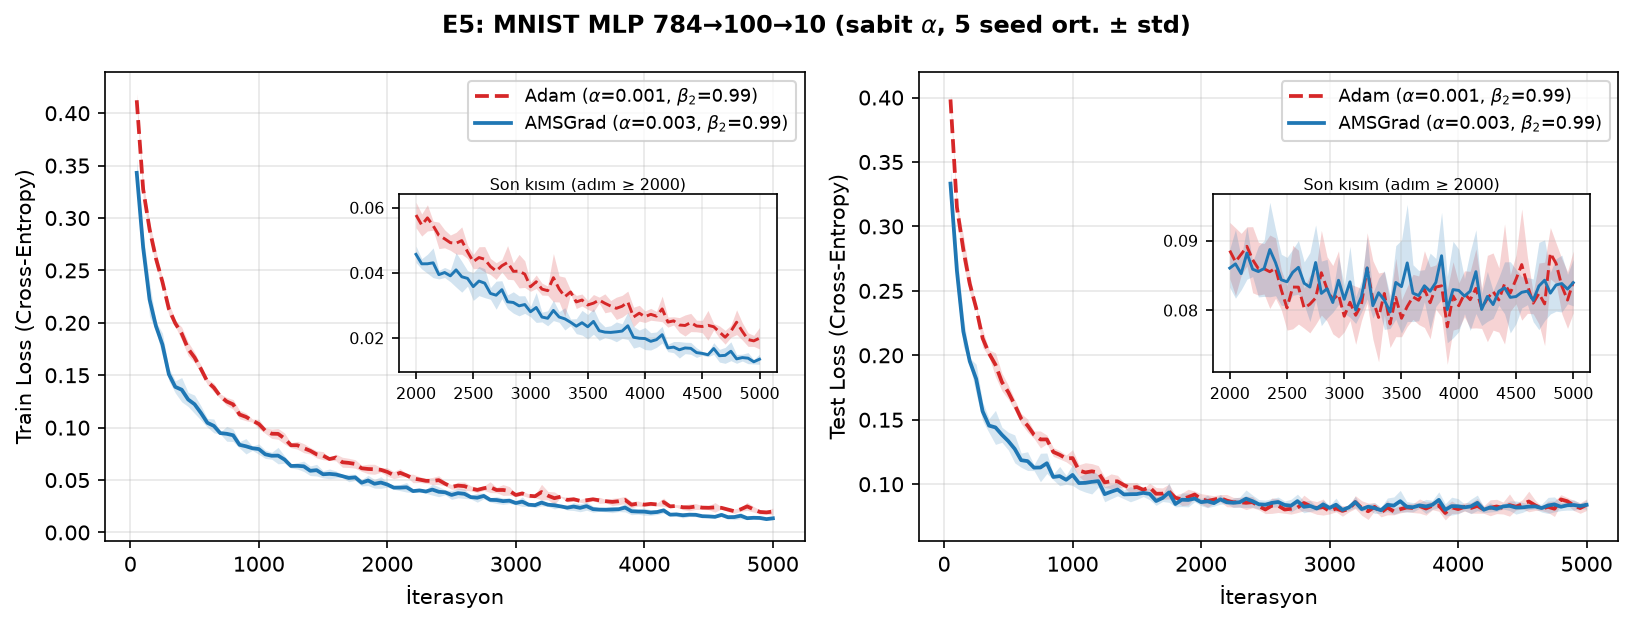

In [5]:
fig = plot_train_test_curves(
    final_df,
    title="E5: MNIST MLP 784→100→10 (sabit $\\alpha$, 5 seed ort. ± std)",
    save_name="e5",
    figures_dir=FIGURES_DIR,
    best_cfgs=best_cfgs,
    min_step=50,
    zoom_from=2000,
)
plt.show()
assert os.path.isfile(os.path.join(FIGURES_DIR, "e5.png"))
assert os.path.isfile(os.path.join(FIGURES_DIR, "e5.pdf"))